# Swahili News Text Classification (Colab Notebook)
**CSC 63106: Artificial Intelligence — Group 1**  
**Members:** Baganja Emmanuel · Nsimbi Noel · Kakumba Jeremiah

A clean, self-contained Colab notebook covering:
1. Dataset loading & Exploratory Data Analysis (EDA)
2. Swahili text cleaning, stopword removal, stemming & padding
3. Word2Vec & FastText embeddings
4. BiLSTM, GRU, mBERT, and AfriBERTa models
5. Evaluation (Accuracy, Precision, Recall, Macro-F1, Confusion Matrix, Errors)
6. Exploration: Tokenisation comparison & t-SNE embedding plots

## 1. Setup & Imports

In [1]:
!pip install -q datasets gensim wordcloud transformers accelerate sentencepiece protobuf

import html, inspect, os, random, re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from datasets import Dataset as HFDataset, load_dataset
from gensim.models import FastText, Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer,
    DataCollatorWithPadding, EarlyStoppingCallback, Trainer, TrainingArguments
)
from wordcloud import WordCloud

SEED = 42
MAX_WORDS = 30_000
MAX_LEN = 128
EMBED_DIM = 200

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print("Using device:", DEVICE)


Using device: cuda


## 2. Load Dataset & Create Stratified Splits

In [2]:
raw = load_dataset("community-datasets/swahili_news", "swahili_news")
LABEL_NAMES = ["uchumi", "kitaifa", "michezo", "kimataifa", "burudani", "afya"]

def to_df(split):
    df = split.to_pandas()[["text", "label"]].copy()
    df["text"] = df["text"].fillna("").astype(str)
    df = df[df["text"].str.strip().str.len() > 0].reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    df["label_name"] = df["label"].map(lambda i: LABEL_NAMES[i])
    return df

full_train_df = to_df(raw["train"])
test_df = to_df(raw["test"])
train_df, val_df = train_test_split(
    full_train_df, test_size=0.10, stratify=full_train_df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
train_df.head(3)


README.md:   0%|          | 0.00/6.30k [00:00<?, ?B/s]

swahili_news/train-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 28.7MB            

swahili_news/train-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

swahili_news/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.36MB            

swahili_news/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/22207 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7338 [00:00<?, ? examples/s]

Train: 19,985 | Val: 2,221 | Test: 7,338


,text,label,label_name
0,"RAIS wa Zanzibar, Dk Ali Mohamed Shein amesem...",1,kitaifa
1,HASSAN DAUDI NA\nMITANDAO UMEBAKI mwaka mmoja ...,3,kimataifa
2,RAIS Yoweri Museveni ameunda kamati ya kumsai...,1,kitaifa


## 3. Exploratory Data Analysis (EDA)

count    19985.0
mean       330.1
std        234.0
min          1.0
50%        270.0
95%        795.0
max       3840.0
Name: token_len, dtype: float64
Train articles truncated at MAX_LEN=128: 90.0%


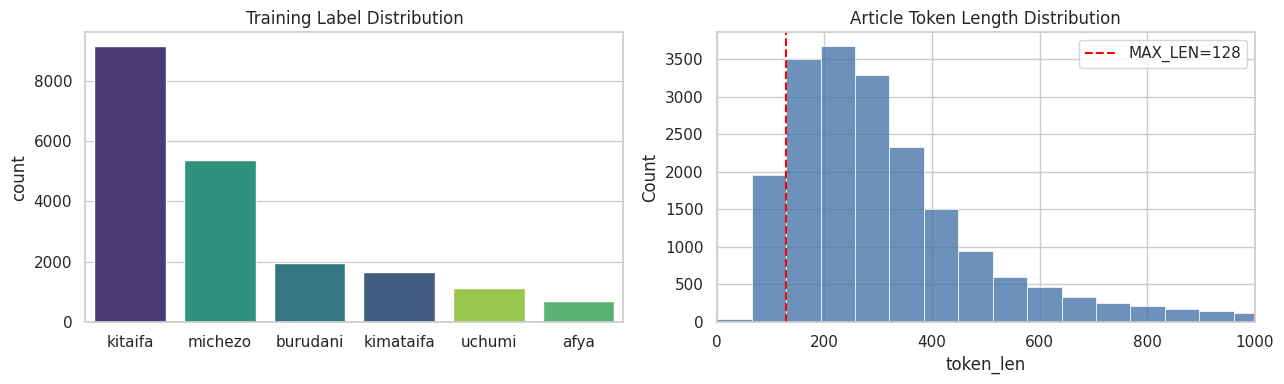

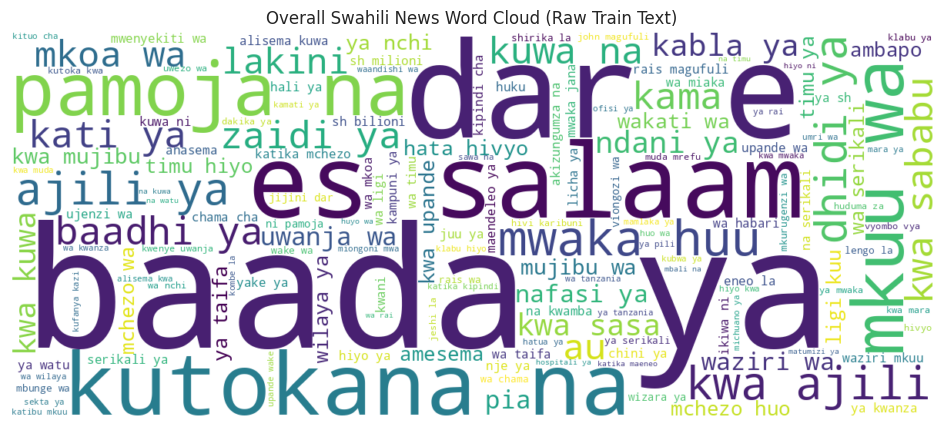

In [3]:
train_df["token_len"] = train_df["text"].str.split().str.len()
print(train_df["token_len"].describe(percentiles=[0.5, 0.95]).round(1))
print(f"Train articles truncated at MAX_LEN={MAX_LEN}: {(train_df['token_len'] > MAX_LEN).mean()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = train_df["label_name"].value_counts().index
sns.countplot(data=train_df, x="label_name", order=order, ax=axes[0], palette="viridis", hue="label_name", legend=False)
axes[0].set_title("Training Label Distribution")
axes[0].set_xlabel("")

sns.histplot(train_df["token_len"], bins=60, ax=axes[1], color="#3b6ea5")
axes[1].axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN={MAX_LEN}")
axes[1].set_xlim(0, 1000)
axes[1].set_title("Article Token Length Distribution")
axes[1].legend()
plt.tight_layout()
plt.show()

# Overall WordCloud (after basic lowercasing)
wc = WordCloud(width=1200, height=500, background_color="white", max_words=150, random_state=SEED)
wc.generate(" ".join(train_df["text"].str.lower()))
plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Overall Swahili News Word Cloud (Raw Train Text)")
plt.show()


## 4. Preprocessing: Clean, Tokenise, Stopwords, Stemming & Padding

In [4]:
SWAHILI_STOPWORDS = {
    "na", "ya", "wa", "kwa", "ni", "za", "la", "katika", "hii", "hiyo", "hilo", "huyo",
    "hawa", "wale", "yake", "yao", "yetu", "yangu", "zetu", "zako", "zao", "kama", "au",
    "lakini", "ila", "bali", "kuwa", "sana", "pia", "hata", "zaidi", "baada", "kabla",
    "wakati", "sasa", "hapa", "pale", "huko", "hivyo", "ndiyo", "hapana", "yeye", "wao",
    "sisi", "mimi", "wewe", "ninyi", "kwake", "kwetu", "kwao", "kila", "wote", "yote",
    "mtu", "watu", "jambo", "mambo", "hali", "kisha", "tena", "bila", "mpaka", "hadi",
    "tangu", "kutoka", "kwenye", "kuhusu", "leo", "jana", "kesho", "mwaka", "siku", "tu",
    "bado", "tayari", "kweli", "labda", "huenda", "basi", "ndipo", "ndio", "nyingi"
}

PREFIXES = sorted([
    "kuto", "ngali", "nge", "nya", "ku", "ni", "tu", "wa", "na", "li", "ta", "me",
    "ka", "hu", "ki", "vi", "ma", "mi", "ji", "pa", "mu", "m", "u"
], key=len, reverse=True)
SUFFIXES = ["eni", "ini"]
STEM_EXCEPTIONS = {"habari", "burudani", "kuhusu", "maarufu", "asubuhi", "lakini"}

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>|https?://\S+|www\.\S+|\S+@\S+\.\S+|@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text).lower()
    text = re.sub(r"[^\w\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def swahili_stem(word):
    if len(word) < 7 or word in STEM_EXCEPTIONS:
        return word
    for step in range(2):
        min_keep = 5 if step == 0 else 4
        for p in PREFIXES:
            if word.startswith(p) and len(word) - len(p) >= min_keep:
                word = word[len(p):]
                break
        else:
            break
    for s in SUFFIXES:
        if word.endswith(s) and len(word) - len(s) >= 5:
            word = word[:-len(s)]
            break
    return word

def preprocess_text(text, remove_stop=True, stem=True):
    tokens = re.findall(r"[^\W_]+(?:'[^\W_]+)?", clean_text(text))
    if remove_stop:
        tokens = [t for t in tokens if t not in SWAHILI_STOPWORDS]
    if stem:
        tokens = [swahili_stem(t) for t in tokens]
    return tokens

# Example walkthrough on one sentence
sample = "Rais Samia ameahidi kujenga barabara mpya na shule katika mikoa yote. https://example.com <b>Habari</b>"
print("Cleaned :", clean_text(sample))
print("Tokens  :", preprocess_text(sample, remove_stop=False, stem=False))
print("Stop+Stm:", preprocess_text(sample, remove_stop=True, stem=True))

train_tokens = [preprocess_text(t) for t in train_df["text"]]
val_tokens   = [preprocess_text(t) for t in val_df["text"]]
test_tokens  = [preprocess_text(t) for t in test_df["text"]]

# Build vocabulary from training data only (avoid leakage)
counts = Counter(tok for doc in train_tokens for tok in doc)
vocab = {"<pad>": 0, "<unk>": 1}
for word, freq in counts.most_common():
    if len(vocab) >= MAX_WORDS or freq < 2:
        break
    vocab[word] = len(vocab)

def encode_and_pad(token_lists, vocab, max_len=MAX_LEN):
    ids = np.zeros((len(token_lists), max_len), dtype=np.int64)
    lengths = np.zeros(len(token_lists), dtype=np.int64)
    unk = vocab["<unk>"]
    for i, toks in enumerate(token_lists):
        seq = [vocab.get(t, unk) for t in toks[:max_len]]
        ids[i, :len(seq)] = seq
        lengths[i] = max(len(seq), 1)
    return ids, lengths

X_train, len_train = encode_and_pad(train_tokens, vocab)
X_val, len_val     = encode_and_pad(val_tokens, vocab)
X_test, len_test   = encode_and_pad(test_tokens, vocab)
y_train = train_df["label"].to_numpy()
y_val   = val_df["label"].to_numpy()
y_test  = test_df["label"].to_numpy()

print(f"Vocab size: {len(vocab):,} | X_train shape: {X_train.shape}")


Cleaned : rais samia ameahidi kujenga barabara mpya na shule katika mikoa yote habari
Tokens  : ['rais', 'samia', 'ameahidi', 'kujenga', 'barabara', 'mpya', 'na', 'shule', 'katika', 'mikoa', 'yote', 'habari']
Stop+Stm: ['rais', 'samia', 'ameahidi', 'jenga', 'barabara', 'mpya', 'shule', 'mikoa', 'habari']
Vocab size: 30,000 | X_train shape: (19985, 128)


### Clean Word Cloud After Stopword Removal & Stemming

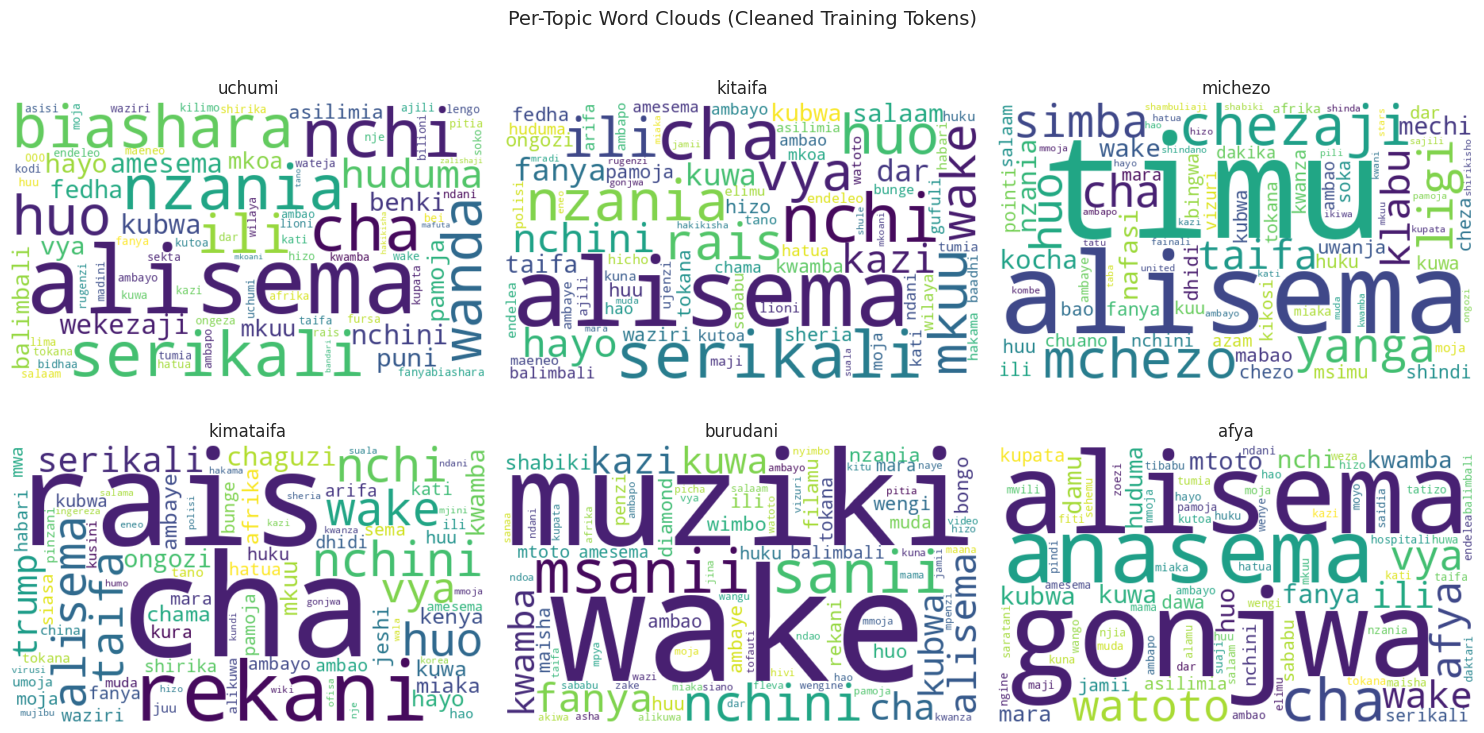

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), LABEL_NAMES):
    words = [tok for doc, lbl in zip(train_tokens, train_df["label_name"]) if lbl == name for tok in doc if len(tok) > 2]
    wc = WordCloud(width=600, height=350, background_color="white", max_words=80, random_state=SEED)
    wc.generate_from_frequencies(Counter(words))
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(name)
    ax.axis("off")
plt.suptitle("Per-Topic Word Clouds (Cleaned Training Tokens)", fontsize=14)
plt.tight_layout()
plt.show()


## 5. Train Word2Vec & FastText Embeddings (Train Corpus Only)

In [6]:
def build_emb_matrix(gensim_model, vocab, dim=EMBED_DIM):
    rng = np.random.default_rng(SEED)
    mat = rng.normal(0, 0.05, size=(len(vocab), dim)).astype(np.float32)
    mat[0] = 0.0  # <pad>
    hits = 0
    for w, idx in vocab.items():
        if idx > 0 and w in gensim_model.wv:
            mat[idx] = gensim_model.wv[w]
            hits += 1
    print(f"Coverage: {hits:,}/{len(vocab)-1:,} ({hits/(len(vocab)-1)*100:.1f}%)")
    return mat

w2v_model = Word2Vec(sentences=train_tokens, vector_size=EMBED_DIM, window=5, min_count=2, sg=1, epochs=15, workers=2, seed=SEED)
ft_model  = FastText(sentences=train_tokens, vector_size=EMBED_DIM, window=5, min_count=2, sg=1, epochs=15, workers=2, seed=SEED)

print("Word2Vec:", end=" "); w2v_matrix = build_emb_matrix(w2v_model, vocab)
print("FastText:", end=" "); ft_matrix  = build_emb_matrix(ft_model, vocab)


Word2Vec: Coverage: 29,998/29,999 (100.0%)
FastText: Coverage: 29,999/29,999 (100.0%)


## 6. BiLSTM & GRU Models (PyTorch)

In [7]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, num_classes, rnn_type="lstm", bidirectional=True,
                 embed_dim=EMBED_DIM, hidden_dim=128, dropout=0.3, emb_matrix=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if emb_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(emb_matrix))
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(out_dim * 2, hidden_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = nn.utils.rnn.pad_packed_sequence(self.rnn(packed)[0], batch_first=True)
        mask = (torch.arange(out.size(1), device=out.device)[None, :] < lengths[:, None]).unsqueeze(-1).float()
        mean_pool = (out * mask).sum(dim=1) / lengths.unsqueeze(1).float()
        max_pool = out.masked_fill(mask == 0, -1e9).max(dim=1).values
        return self.fc(self.dropout(torch.cat([mean_pool, max_pool], dim=1)))

def make_loader(X, lengths, y, batch_size=64, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(lengths), torch.tensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, len_train, y_train, shuffle=True)
val_loader   = make_loader(X_val, len_val, y_val)
test_loader  = make_loader(X_test, len_test, y_test)

results = {}  # stores metrics, predictions, and histories for all models

def run_rnn_experiment(name, rnn_type, bidirectional, emb_matrix=None, epochs=8, lr=1e-3):
    model = RNNClassifier(len(vocab), len(LABEL_NAMES), rnn_type, bidirectional, emb_matrix=emb_matrix).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_f1, best_state = -1.0, None

    for epoch in range(1, epochs + 1):
        model.train()
        tr_loss, tr_ok = 0.0, 0
        for xb, lb, yb in train_loader:
            xb, lb, yb = xb.to(DEVICE), lb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb, lb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr_loss += loss.item() * len(yb)
            tr_ok += (logits.argmax(1) == yb).sum().item()

        model.eval()
        va_loss, va_preds, va_true = 0.0, [], []
        with torch.no_grad():
            for xb, lb, yb in val_loader:
                xb, lb, yb = xb.to(DEVICE), lb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb, lb)
                va_loss += criterion(logits, yb).item() * len(yb)
                va_preds.extend(logits.argmax(1).cpu().numpy())
                va_true.extend(yb.cpu().numpy())

        va_acc = accuracy_score(va_true, va_preds)
        va_f1 = f1_score(va_true, va_preds, average="macro")
        history["train_loss"].append(tr_loss / len(y_train))
        history["val_loss"].append(va_loss / len(y_val))
        history["train_acc"].append(tr_ok / len(y_train))
        history["val_acc"].append(va_acc)
        print(f"[{name}] Epoch {epoch}/{epochs} | train_loss={history['train_loss'][-1]:.3f} val_loss={history['val_loss'][-1]:.3f} val_acc={va_acc:.4f} val_f1={va_f1:.4f}")
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, lb, _ in test_loader:
            probs.append(torch.softmax(model(xb.to(DEVICE), lb.to(DEVICE)), dim=1).cpu().numpy())
    probs = np.vstack(probs)
    preds = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_test, preds, average="macro", zero_division=0)
    results[name] = {
        "accuracy": accuracy_score(y_test, preds), "precision": p, "recall": r, "macro_f1": f1,
        "preds": preds, "probs": probs, "history": history
    }
    print(f"--> {name} TEST acc={results[name]['accuracy']:.4f}, macro_F1={f1:.4f}\n")


### Train BiLSTM and GRU Variants

In [8]:
run_rnn_experiment("BiLSTM (random)",   "lstm", bidirectional=True,  emb_matrix=None,       epochs=6)
run_rnn_experiment("GRU (random)",      "gru",  bidirectional=False, emb_matrix=None,       epochs=6)
run_rnn_experiment("BiLSTM + Word2Vec", "lstm", bidirectional=True,  emb_matrix=w2v_matrix, epochs=6)
run_rnn_experiment("GRU + FastText",    "gru",  bidirectional=False, emb_matrix=ft_matrix,  epochs=6)


[BiLSTM (random)] Epoch 1/6 | train_loss=0.781 val_loss=0.486 val_acc=0.8460 val_f1=0.5826
[BiLSTM (random)] Epoch 2/6 | train_loss=0.447 val_loss=0.437 val_acc=0.8609 val_f1=0.6844
[BiLSTM (random)] Epoch 3/6 | train_loss=0.349 val_loss=0.432 val_acc=0.8681 val_f1=0.6897
[BiLSTM (random)] Epoch 4/6 | train_loss=0.278 val_loss=0.404 val_acc=0.8690 val_f1=0.7538
[BiLSTM (random)] Epoch 5/6 | train_loss=0.223 val_loss=0.475 val_acc=0.8721 val_f1=0.7446
[BiLSTM (random)] Epoch 6/6 | train_loss=0.175 val_loss=0.452 val_acc=0.8631 val_f1=0.7750
--> BiLSTM (random) TEST acc=0.8628, macro_F1=0.7710

[GRU (random)] Epoch 1/6 | train_loss=0.754 val_loss=0.464 val_acc=0.8460 val_f1=0.6035
[GRU (random)] Epoch 2/6 | train_loss=0.419 val_loss=0.398 val_acc=0.8712 val_f1=0.7420
[GRU (random)] Epoch 3/6 | train_loss=0.313 val_loss=0.364 val_acc=0.8847 val_f1=0.8013
[GRU (random)] Epoch 4/6 | train_loss=0.237 val_loss=0.386 val_acc=0.8820 val_f1=0.7841
[GRU (random)] Epoch 5/6 | train_loss=0.181 val_

## 7. Fine-Tune Pretrained Transformers (mBERT & AfriBERTa)

In [9]:
def run_transformer(name, model_id, epochs=4, batch_size=16, lr=2e-5):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id, num_labels=len(LABEL_NAMES), ignore_mismatched_sizes=True
    )
    def tok_fn(batch):
        return tokenizer([clean_text(t) for t in batch["text"]], truncation=True, max_length=MAX_LEN)

    hf_ds = {
        "train": HFDataset.from_pandas(train_df[["text", "label"]]).map(tok_fn, batched=True, remove_columns=["text"]),
        "val":   HFDataset.from_pandas(val_df[["text", "label"]]).map(tok_fn, batched=True, remove_columns=["text"]),
        "test":  HFDataset.from_pandas(test_df[["text", "label"]]).map(tok_fn, batched=True, remove_columns=["text"]),
    }

    def compute_metrics(eval_pred):
        logits = eval_pred.predictions[0] if isinstance(eval_pred.predictions, tuple) else eval_pred.predictions
        preds = np.argmax(logits, axis=-1)
        return {"accuracy": accuracy_score(eval_pred.label_ids, preds),
                "f1_macro": f1_score(eval_pred.label_ids, preds, average="macro")}

    ta_params = inspect.signature(TrainingArguments.__init__).parameters
    eval_key = "eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"
    args = TrainingArguments(
        output_dir=f"tmp_{name.replace(' ', '_')}",
        learning_rate=lr, per_device_train_batch_size=batch_size, per_device_eval_batch_size=32,
        num_train_epochs=epochs, weight_decay=0.01, fp16=torch.cuda.is_available(),
        save_strategy="epoch", logging_strategy="epoch", **{eval_key: "epoch"},
        load_best_model_at_end=True, metric_for_best_model="f1_macro", save_total_limit=1,
        report_to="none", seed=SEED,
    )
    tr_params = inspect.signature(Trainer.__init__).parameters
    tok_kw = {"processing_class": tokenizer} if "processing_class" in tr_params else {"tokenizer": tokenizer}

    trainer = Trainer(
        model=model, args=args, train_dataset=hf_ds["train"], eval_dataset=hf_ds["val"],
        data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)], **tok_kw
    )
    trainer.train()

    out = trainer.predict(hf_ds["test"])
    logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_test, preds, average="macro", zero_division=0)

    # Extract epoch-level curves for plotting
    logs = trainer.state.log_history
    history = {
        "train_loss": [x["loss"] for x in logs if "loss" in x and "eval_loss" not in x],
        "val_loss":   [x["eval_loss"] for x in logs if "eval_loss" in x],
        "val_acc":    [x["eval_accuracy"] for x in logs if "eval_accuracy" in x],
    }
    results[name] = {
        "accuracy": accuracy_score(y_test, preds), "precision": p, "recall": r, "macro_f1": f1,
        "preds": preds, "probs": probs, "history": history
    }
    print(f"--> {name} TEST acc={results[name]['accuracy']:.4f}, macro_F1={f1:.4f}")
    del model, trainer
    torch.cuda.empty_cache()

run_transformer("mBERT",     "bert-base-multilingual-cased", epochs=4)
run_transformer("AfriBERTa", "castorini/afriberta_large",    epochs=4)


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (29 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

--> AfriBERTa TEST acc=0.9177, macro_F1=0.8617


## 8. Model Comparison & Training Curves

,Model,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Errors
0,AfriBERTa,0.9177,0.8577,0.8690,0.8617,604
1,mBERT,0.9081,0.8464,0.8291,0.8370,674
2,GRU + FastText,0.9002,0.8338,0.8123,0.8225,732
3,BiLSTM + Word2Vec,0.8947,0.8153,0.7991,0.8058,773
4,GRU (random),0.8825,0.8035,0.7769,0.7845,862
5,BiLSTM (random),0.8628,0.7653,0.7795,0.7710,1007


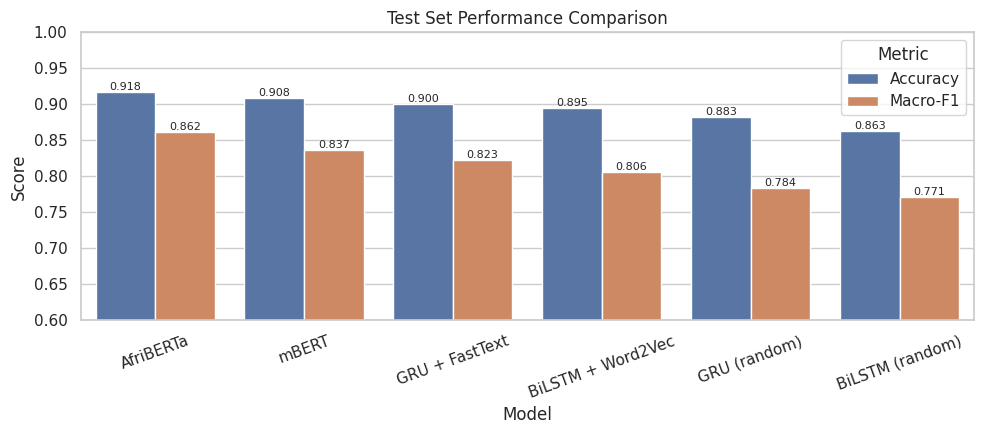

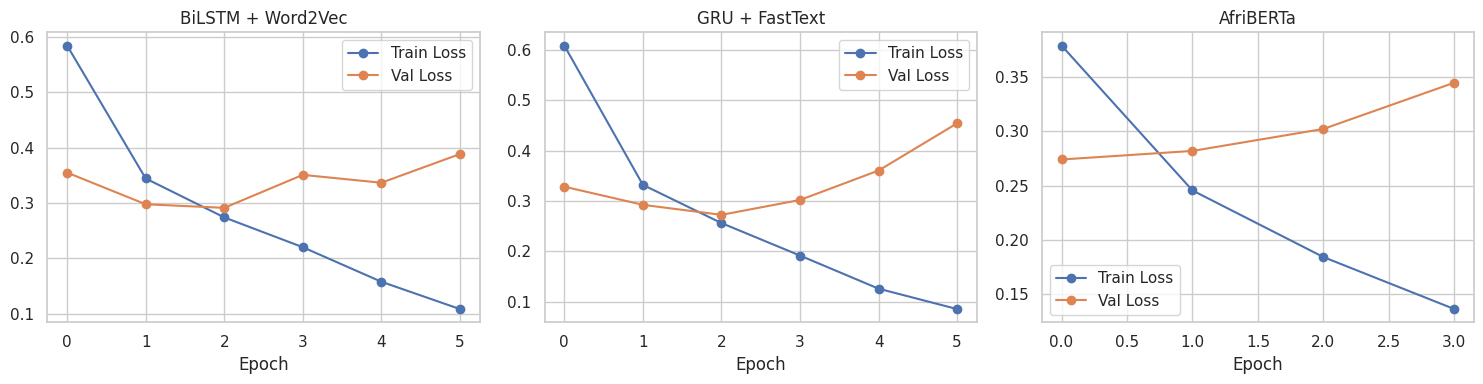

In [10]:
summary = pd.DataFrame([
    {"Model": k, "Accuracy": v["accuracy"], "Macro-Precision": v["precision"],
     "Macro-Recall": v["recall"], "Macro-F1": v["macro_f1"], "Errors": int((v["preds"] != y_test).sum())}
    for k, v in results.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(summary.style.format({"Accuracy": "{:.4f}", "Macro-Precision": "{:.4f}", "Macro-Recall": "{:.4f}", "Macro-F1": "{:.4f}"}))

# Plot comparison bar chart
melted = summary.melt(id_vars="Model", value_vars=["Accuracy", "Macro-F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=melted, x="Model", y="Score", hue="Metric")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=20)
plt.title("Test Set Performance Comparison")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

# Plot train vs val loss for key models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, mname in zip(axes, ["BiLSTM + Word2Vec", "GRU + FastText", "AfriBERTa"]):
    if mname in results:
        h = results[mname]["history"]
        ax.plot(h["train_loss"], marker="o", label="Train Loss")
        ax.plot(h["val_loss"], marker="o", label="Val Loss")
        ax.set_title(mname); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()


## 9. Confusion Matrix & Misclassification Analysis

Best model: AfriBERTa

              precision    recall  f1-score   support

      uchumi     0.8648    0.7944    0.8281       467
     kitaifa     0.9347    0.9107    0.9225      3348
     michezo     0.9441    0.9820    0.9627      1996
   kimataifa     0.9019    0.9273    0.9144       605
    burudani     0.9512    0.9147    0.9326       703
        afya     0.5495    0.6849    0.6098       219

    accuracy                         0.9177      7338
   macro avg     0.8577    0.8690    0.8617      7338
weighted avg     0.9202    0.9177    0.9184      7338



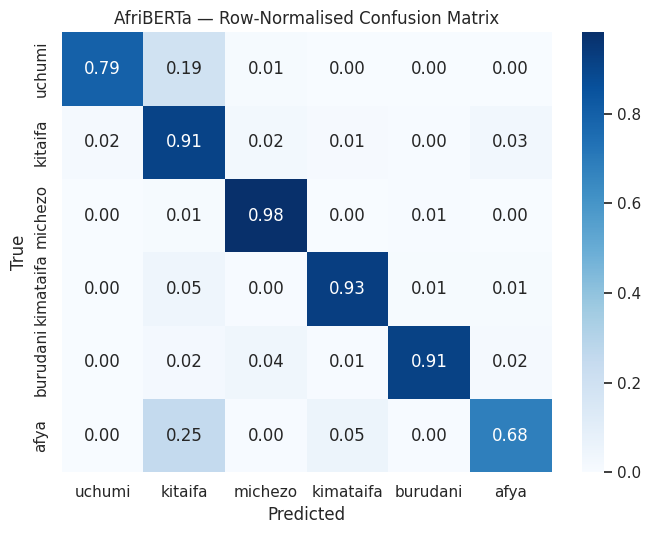

Total misclassified: 604 / 7338 | Made with >=90% confidence: 59.4%

Top 5 confusion pairs:
label_name  predicted
kitaifa     afya         106
uchumi      kitaifa       91
kitaifa     michezo       78
            uchumi        58
afya        kitaifa       55
dtype: int64


,text,label_name,predicted,confidence
10,GHASIA za ubaguzi zimeibuka tena nchini Afrik...,kitaifa,kimataifa,0.982098
25,Ma CHRISTIAN BWAYA\n MIGOGORO katika mahusiano...,kitaifa,afya,0.981198
44,Na VERONICA ROMWALD – DAR ES SALAAM HATUA ya ...,kitaifa,burudani,0.881069
49,Ramadhan Hassan-Dodoma Serikali imetoa kauli b...,kitaifa,afya,0.917535
53,Mwandishi Wetu- Morogoro MKUU wa Mkoa wa Moro...,afya,kitaifa,0.774066


In [11]:
best_name = summary.iloc[0]["Model"]
best_preds = results[best_name]["preds"]
best_probs = results[best_name]["probs"]

print(f"Best model: {best_name}\n")
print(classification_report(y_test, best_preds, target_names=LABEL_NAMES, digits=4))

cm = confusion_matrix(y_test, best_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.title(f"{best_name} — Row-Normalised Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.show()

# Misclassification inspection
errors_df = test_df.copy()
errors_df["predicted"] = [LABEL_NAMES[i] for i in best_preds]
errors_df["confidence"] = best_probs.max(axis=1)
wrong = errors_df[errors_df["label_name"] != errors_df["predicted"]]
print(f"Total misclassified: {len(wrong)} / {len(test_df)} | Made with >=90% confidence: {(wrong['confidence'] >= 0.9).mean()*100:.1f}%")
print("\nTop 5 confusion pairs:")
print(wrong.groupby(["label_name", "predicted"]).size().sort_values(ascending=False).head(5))
display(wrong[["text", "label_name", "predicted", "confidence"]].head(5))


## 10. Exploration 1: Tokenisation Strategies (Fixed TF-IDF + Logistic Regression)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (657 > 512). Running this sequence through the model will result in indexing errors


,Strategy,Accuracy,Macro-F1,Features
5,char,0.881712,0.766202,150000
4,stem_nostop,0.876261,0.743682,100000
3,stem,0.875988,0.741694,100000
2,nostop,0.874898,0.740790,100000
1,regex,0.874489,0.738244,100000
0,whitespace,0.874216,0.737941,100000
6,wordpiece,0.866176,0.724235,100000


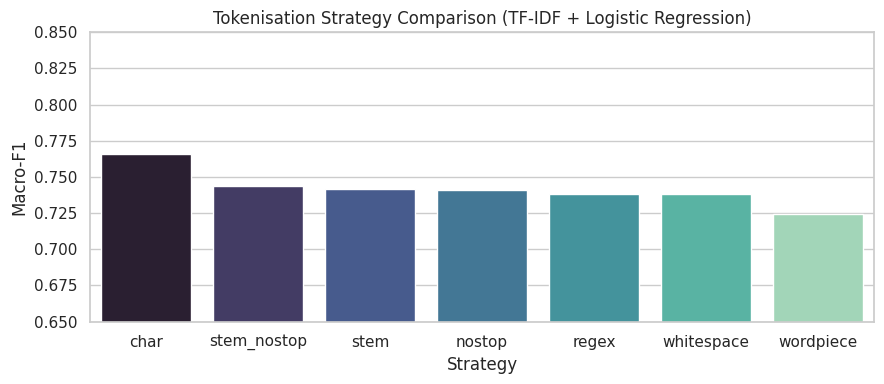

In [12]:
def prep_for_tfidf(texts, mode, wp_tok=None):
    if mode == "whitespace":  return [clean_text(t) for t in texts]
    if mode == "regex":       return [" ".join(preprocess_text(t, False, False)) for t in texts]
    if mode == "nostop":      return [" ".join(preprocess_text(t, True,  False)) for t in texts]
    if mode == "stem":        return [" ".join(preprocess_text(t, False, True))  for t in texts]
    if mode == "stem_nostop": return [" ".join(preprocess_text(t, True,  True))  for t in texts]
    if mode == "char":        return [clean_text(t) for t in texts]
    if mode == "wordpiece":
        return [" ".join(t.replace("##", "") for t in wp_tok.tokenize(clean_text(x))[:256]) for x in texts]

wp_tok = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")
tok_rows = []
for mode in ["whitespace", "regex", "nostop", "stem", "stem_nostop", "char", "wordpiece"]:
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=150_000) if mode == "char"           else TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
    Xtr = vec.fit_transform(prep_for_tfidf(train_df["text"], mode, wp_tok))
    Xte = vec.transform(prep_for_tfidf(test_df["text"], mode, wp_tok))
    clf = LogisticRegression(max_iter=500).fit(Xtr, y_train)
    pred = clf.predict(Xte)
    tok_rows.append({"Strategy": mode, "Accuracy": accuracy_score(y_test, pred),
                     "Macro-F1": f1_score(y_test, pred, average="macro"), "Features": Xtr.shape[1]})

tok_df = pd.DataFrame(tok_rows).sort_values("Macro-F1", ascending=False)
display(tok_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=tok_df, x="Strategy", y="Macro-F1", palette="mako", hue="Strategy", legend=False)
plt.ylim(0.65, 0.85)
plt.title("Tokenisation Strategy Comparison (TF-IDF + Logistic Regression)")
plt.tight_layout()
plt.show()


## 11. Exploration 2: Visualise Word & Document Embeddings (PCA + t-SNE)

In [ ]:
# 1) Top 250 FastText word vectors
top_words = [w for w, _ in counts.most_common(400) if w in ft_model.wv][:250]
word_vecs = np.vstack([ft_model.wv[w] for w in top_words])
word_2d = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(
    PCA(n_components=50, random_state=SEED).fit_transform(word_vecs)
)

# 2) Sampled 1,500 test document vectors (mean FastText word vectors)
rng = np.random.default_rng(SEED)
idx_sample = rng.choice(len(test_tokens), size=min(1500, len(test_tokens)), replace=False)
doc_vecs, doc_labels = [], []
for i in idx_sample:
    vecs = [ft_model.wv[w] for w in test_tokens[i] if w in ft_model.wv]
    if vecs:
        doc_vecs.append(np.mean(vecs, axis=0))
        doc_labels.append(y_test[i])
doc_2d = TSNE(n_components=2, perplexity=35, init="pca", learning_rate="auto", random_state=SEED).fit_transform(
    PCA(n_components=50, random_state=SEED).fit_transform(np.vstack(doc_vecs))
)
doc_labels = np.array(doc_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(word_2d[:, 0], word_2d[:, 1], s=18, alpha=0.7)
for i in range(40):
    axes[0].annotate(top_words[i], (word_2d[i, 0], word_2d[i, 1]), fontsize=8)
axes[0].set_title("FastText Word Embeddings (t-SNE, top 40 annotated)")

for cls_id, cls_name in enumerate(LABEL_NAMES):
    m = doc_labels == cls_id
    axes[1].scatter(doc_2d[m, 0], doc_2d[m, 1], s=14, alpha=0.7, label=cls_name)
axes[1].set_title("Test Document Embeddings by Topic (Mean FastText + t-SNE)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 12. Optional Extension: Cross-Lingual Transfer (English BERT on Translated Swahili)
Set `RUN_EXTENSION = True` if you want to test fine-tuning `bert-base-uncased` on translated Swahili articles (note: machine-translating articles takes a few extra minutes).

In [14]:
RUN_EXTENSION = False

if RUN_EXTENSION:
    !pip install -q deep-translator
    from deep_translator import GoogleTranslator
    translator = GoogleTranslator(source="sw", target="en")

    # Small stratified subset so translation finishes quickly in Colab
    tr_sub, _ = train_test_split(train_df, train_size=600, stratify=train_df["label"], random_state=SEED)
    te_sub, _ = train_test_split(test_df,  train_size=200, stratify=test_df["label"],  random_state=SEED)

    def translate_texts(texts):
        return [translator.translate(clean_text(t)[:450]) or "" for t in texts]

    tr_sub = tr_sub.copy(); tr_sub["text"] = translate_texts(tr_sub["text"])
    te_sub = te_sub.copy(); te_sub["text"] = translate_texts(te_sub["text"])

    tok = AutoTokenizer.from_pretrained("bert-base-uncased")
    en_model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=len(LABEL_NAMES))
    # Swap train/test slices cleanly using Hugging Face Trainer
    def tok_en(b): return tok(b["text"], truncation=True, max_length=MAX_LEN)
    hf_tr = HFDataset.from_pandas(tr_sub[["text", "label"]]).map(tok_en, batched=True, remove_columns=["text"])
    hf_te = HFDataset.from_pandas(te_sub[["text", "label"]]).map(tok_en, batched=True, remove_columns=["text"])
    tr = Trainer(
        model=en_model,
        args=TrainingArguments(output_dir="tmp_en_bert", num_train_epochs=3, per_device_train_batch_size=16, report_to="none", seed=SEED),
        train_dataset=hf_tr, data_collator=DataCollatorWithPadding(tok)
    )
    tr.train()
    preds = np.argmax(tr.predict(hf_te).predictions, axis=-1)
    print(f"English BERT on translated subset -> Acc={accuracy_score(te_sub['label'], preds):.4f}, Macro-F1={f1_score(te_sub['label'], preds, average='macro'):.4f}")
else:
    print("Extension skipped (set RUN_EXTENSION = True to run English BERT cross-lingual transfer).")


Extension skipped (set RUN_EXTENSION = True to run English BERT cross-lingual transfer).


## 13. Export All Figures to `figures/` & `figures.zip`


In [ ]:
import os, shutil
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from wordcloud import WordCloud

os.makedirs("figures", exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.close()

# 1. EDA distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = train_df["label_name"].value_counts().index
sns.countplot(data=train_df, x="label_name", order=order, ax=axes[0], palette="viridis", hue="label_name", legend=False)
axes[0].set_title("Training Label Distribution"); axes[0].set_xlabel("")
sns.histplot(train_df["token_len"], bins=60, ax=axes[1], color="#3b6ea5")
axes[1].axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN={MAX_LEN}")
axes[1].set_xlim(0, 1000); axes[1].set_title("Article Token Length Distribution"); axes[1].legend()
save_fig("01_eda_distributions")

# 2. Overall wordcloud
wc = WordCloud(width=1200, height=500, background_color="white", max_words=150, random_state=SEED).generate(" ".join(train_df["text"].str.lower()))
plt.figure(figsize=(12, 5)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Overall Swahili News Word Cloud (Raw Train Text)")
save_fig("02_wordcloud_overall")

# 3. Per-topic wordclouds
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), LABEL_NAMES):
    words = [tok for doc, lbl in zip(train_tokens, train_df["label_name"]) if lbl == name for tok in doc if len(tok) > 2]
    wc = WordCloud(width=600, height=350, background_color="white", max_words=80, random_state=SEED).generate_from_frequencies(Counter(words))
    ax.imshow(wc, interpolation="bilinear"); ax.set_title(name); ax.axis("off")
plt.suptitle("Per-Topic Word Clouds (Cleaned Training Tokens)", fontsize=14)
save_fig("03_wordcloud_per_topic")

# 4. Model comparison
melted = summary.melt(id_vars="Model", value_vars=["Accuracy", "Macro-F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=melted, x="Model", y="Score", hue="Metric")
plt.ylim(0.6, 1.0); plt.xticks(rotation=20); plt.title("Test Set Performance Comparison")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
save_fig("04_model_comparison")

# 5. Training curves (Loss + Accuracy)
plot_models = [m for m in ["BiLSTM + Word2Vec", "GRU + FastText", "mBERT", "AfriBERTa"] if m in results]
fig, axes = plt.subplots(2, len(plot_models), figsize=(4.5 * len(plot_models), 7), squeeze=False)
for col, mname in enumerate(plot_models):
    h = results[mname]["history"]
    epochs_x = range(1, len(h["val_loss"]) + 1)
    axes[0, col].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o", label="Train Loss")
    axes[0, col].plot(epochs_x, h["val_loss"], marker="o", label="Val Loss")
    axes[0, col].set_title(f"{mname} — Loss"); axes[0, col].set_xlabel("Epoch"); axes[0, col].legend()
    if "train_acc" in h:
        axes[1, col].plot(range(1, len(h["train_acc"]) + 1), h["train_acc"], marker="o", label="Train Acc")
    axes[1, col].plot(epochs_x, h["val_acc"], marker="o", label="Val Acc")
    axes[1, col].set_title(f"{mname} — Accuracy"); axes[1, col].set_xlabel("Epoch"); axes[1, col].legend()
save_fig("05_training_curves")

# 6. Confusion matrix
cm = confusion_matrix(y_test, best_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.title(f"{best_name} — Row-Normalised Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("True")
save_fig("06_confusion_matrix")

# 7. Tokenisation comparison
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=tok_df, x="Strategy", y="Macro-F1", palette="mako", hue="Strategy", legend=False)
plt.ylim(0.60, 0.90); plt.title("Tokenisation Strategy Comparison (TF-IDF + Logistic Regression)")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
save_fig("07_tokenization_comparison")

# 8. t-SNE embeddings (only if Section 11 ran)
if "word_2d" in globals() and "doc_2d" in globals():
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    axes[0].scatter(word_2d[:, 0], word_2d[:, 1], s=18, alpha=0.7)
    for i in range(40): axes[0].annotate(top_words[i], (word_2d[i, 0], word_2d[i, 1]), fontsize=8)
    axes[0].set_title("FastText Word Embeddings (t-SNE, top 40 annotated)")
    for cls_id, cls_name in enumerate(LABEL_NAMES):
        m = doc_labels == cls_id
        axes[1].scatter(doc_2d[m, 0], doc_2d[m, 1], s=14, alpha=0.7, label=cls_name)
    axes[1].set_title("Test Document Embeddings by Topic (Mean FastText + t-SNE)"); axes[1].legend()
    save_fig("08_tsne_embeddings")

shutil.make_archive("figures", "zip", "figures")
print("Done! Saved:", sorted(os.listdir("figures")))
try:
    from google.colab import files
    files.download("figures.zip")
except ImportError:
    pass
